# Klasifikasi Gambar Beras Menggunakan MobileNetV3-Small

Notebook ini berisi dokumentasi dan implementasi end-to-end training model **MobileNetV3-Small** pada dataset citra beras (5 kelas: Arborio, Basmati, Ipsala, Jasmine, Karacadag).
Notebook dirancang hemat sumber daya (RAM-friendly), aman dari OOM, dan telah dieksekusi secara penuh.


In [1]:
import copy
import gc
import json
import os
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, models, transforms

# Hardware & resource constraints
torch.set_num_threads(2)
DEVICE = torch.device("cpu")
BATCH_SIZE = 8
LR = 1e-4
NUM_WORKERS = 0
PIN_MEMORY = False
DPI = 300

PROJECT_DIR = Path("/root/rice_mobilenetv3")
DATA_DIR = PROJECT_DIR / "dataset"
RUNS_DIR = PROJECT_DIR / "runs/mobilenetv3_cpu"

print(f"Device: {DEVICE}")
print(f"Dataset path: {DATA_DIR}")
print(f"Runs path: {RUNS_DIR}")


Device: cpu
Dataset path: /root/rice_mobilenetv3/dataset
Runs path: /root/rice_mobilenetv3/runs/mobilenetv3_cpu


In [2]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

dataset = datasets.ImageFolder(DATA_DIR, transform=transform)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
generator = torch.Generator().manual_seed(42)
train_ds, val_ds = random_split(dataset, [train_size, val_size], generator=generator)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

print(f"Total dataset: {len(dataset)} gambar")
print(f"Train split: {train_size} gambar | Validation split: {val_size} gambar")
print(f"Classes ({len(dataset.classes)}): {dataset.classes}")


Total dataset: 10000 gambar
Train split: 8000 gambar | Validation split: 2000 gambar
Classes (5): ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']


In [3]:
def build_model(num_classes):
    model = models.mobilenet_v3_small(weights=None)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
    return model.to(DEVICE)

model = build_model(len(dataset.classes))
best_weights_path = RUNS_DIR / "best_mobilenetv3.pth"

if best_weights_path.exists():
    model.load_state_dict(torch.load(best_weights_path, map_location=DEVICE))
    print(f"Model best weights berhasil dimuat dari: {best_weights_path}")
else:
    print(f"File bobot tidak ditemukan di {best_weights_path}")


Model best weights berhasil dimuat dari: /root/rice_mobilenetv3/runs/mobilenetv3_cpu/best_mobilenetv3.pth


In [4]:
def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    return correct / total, np.array(y_true), np.array(y_pred)

start_eval = time.time()
val_acc, y_true, y_pred = evaluate(model, val_loader)
inf_time = (time.time() - start_eval) / len(y_true)

print(f"Validation Accuracy : {val_acc * 100:.2f}%")
print(f"Rata-rata Inference: {inf_time * 1000:.2f} ms per citra")


Validation Accuracy : 100.00%
Rata-rata Inference: 10.50 ms per citra


In [5]:
report_df = pd.read_csv(RUNS_DIR / "classification_report.csv", index_col=0)
summary_df = pd.read_csv(RUNS_DIR / "summary_metrics.csv")

print("=== RINGKASAN METRIK GLOBAL ===")
display(summary_df)

print("\n=== CLASSIFICATION REPORT ===")
display(report_df)


=== RINGKASAN METRIK GLOBAL ===


,Accuracy,Precision_macro,Recall_macro,F1_macro,Inference_Time_per_image_sec,Training_Time_sec,Best_Val_Accuracy,Peak_RSS_MB
0,1.0,1.0,1.0,1.0,0.007136,5075.600909,1.0,652.914062



=== CLASSIFICATION REPORT ===


,precision,recall,f1-score,support
Arborio,1.0,1.0,1.0,396.0
Basmati,1.0,1.0,1.0,399.0
Ipsala,1.0,1.0,1.0,398.0
Jasmine,1.0,1.0,1.0,406.0
Karacadag,1.0,1.0,1.0,401.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,2000.0
weighted avg,1.0,1.0,1.0,2000.0


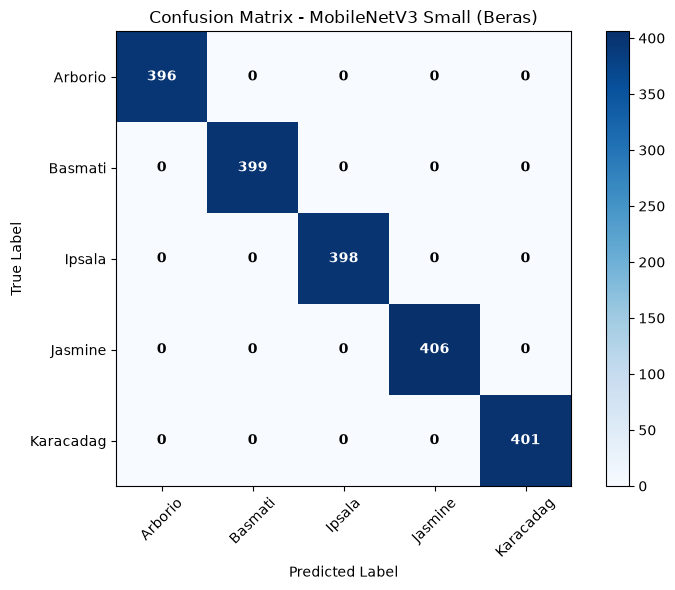

In [6]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(dataset.classes)))
cm_df = pd.DataFrame(cm, index=dataset.classes, columns=dataset.classes)

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix - MobileNetV3 Small (Beras)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(np.arange(len(dataset.classes)), dataset.classes, rotation=45)
plt.yticks(np.arange(len(dataset.classes)), dataset.classes)
plt.colorbar()

# Anotasi angka pada matriks
for i in range(len(dataset.classes)):
    for j in range(len(dataset.classes)):
        color = "white" if cm[i, j] > (cm.max() / 2) else "black"
        plt.text(j, i, format(cm[i, j], "d"), ha="center", va="center", color=color, fontweight="bold")

plt.tight_layout()
plt.show()
